In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Considere el proyecto cuyo cuadro de prelaciones y duraciones (en semanas) se adjunta.

In [4]:
pregunta_1 = "1. Calcule para cada actividad sus fechas más tempranas y más tardías de inicio y fin, y sus holguras total, libre e independiente.  "
pregunta_2 = "2. Determine el camino crítico. ¿Cuántas rutas críticas tiene el proyecto?  "
pregunta_3 = "3. ¿Qué actividades pueden retrasarse sin afectar ni al plazo del proyecto ni al inicio más temprano de ninguna otra actividad? ¿Cuáles pueden retrasarse sin afectar al plazo pero obligando a retrasar a alguna sucesora? Justifíquelo con las holguras.  "
pregunta_4 = "4. La actividad F se retrasa tanto como permite su holgura total (3 semanas). Compruebe que el plazo no cambia y determine qué ocurre con las fechas y holguras de sus sucesoras.  "
pregunta_5 = "5. Suponga que las predecesoras de I terminan en su fecha más tardía. ¿Cuánto puede retrasarse entonces I sin afectar a nadie? Relaciónelo con su holgura independiente.  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Calcule para cada actividad sus fechas más tempranas y más tardías de inicio y fin, y sus holguras total, libre e independiente.  

2. Determine el camino crítico. ¿Cuántas rutas críticas tiene el proyecto?  

3. ¿Qué actividades pueden retrasarse sin afectar ni al plazo del proyecto ni al inicio más temprano de ninguna otra actividad? ¿Cuáles pueden retrasarse sin afectar al plazo pero obligando a retrasar a alguna sucesora? Justifíquelo con las holguras.  

4. La actividad F se retrasa tanto como permite su holgura total (3 semanas). Compruebe que el plazo no cambia y determine qué ocurre con las fechas y holguras de sus sucesoras.  

5. Suponga que las predecesoras de I terminan en su fecha más tardía. ¿Cuánto puede retrasarse entonces I sin afectar a nadie? Relaciónelo con su holgura independiente.  

In [5]:
#| tbl-cap: "Cuadro de datos del enunciado"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration
    ('A'     , '---'      , 8       ),
    ('B'     , '---'      , 8       ),
    ('C'     , '---'      , 3       ),
    ('D'     , 'A,B,C'    , 1       ),
    ('E'     , 'D'        , 8       ),
    ('F'     , 'B'        , 6       ),
    ('G'     , 'C,F'      , 5       ),
    ('H'     , 'E,F'      , 8       ),
    ('I'     , 'G'        , 3       ),
    ('J'     , 'H,I'      , 3       ),
], columns=['activity', 'predecessor', 'duration']).set_index('activity')
datos_enunciado

,predecessor,duration
activity,,
A,---,8
B,---,8
C,---,3
D,"A,B,C",1
E,D,8
F,B,6
G,"C,F",5
H,"E,F",8
I,G,3


# Resolución

In [6]:
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()

## Apartado 1

In [7]:
display(Markdown(pregunta_1))

1. Calcule para cada actividad sus fechas más tempranas y más tardías de inicio y fin, y sus holguras total, libre e independiente.  

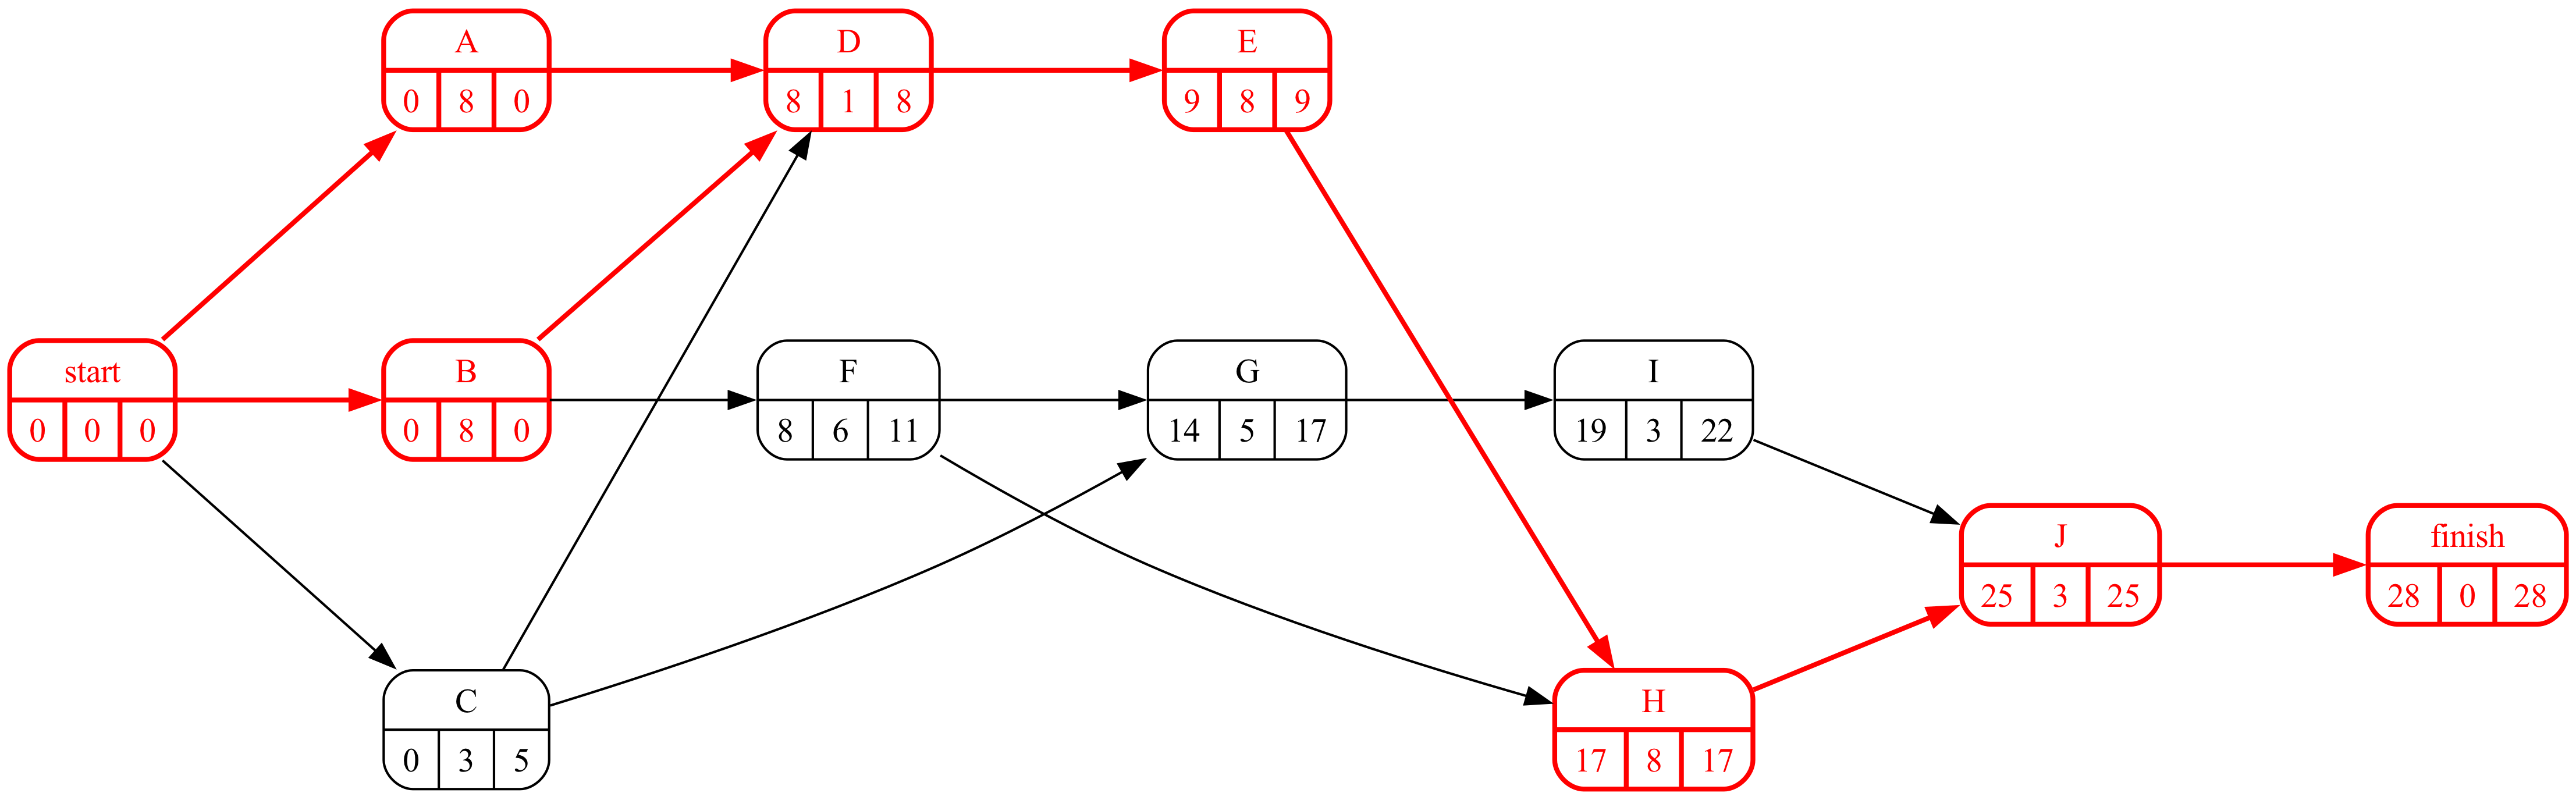

In [8]:
#| fig-cap: "Grafo Roy con tiempos y camino crítico"
#| label: fig-pert
proyecto.roy(durations=datos_proyecto['duration'], ranksep=1.2, nodesep=1.2)

Con las fechas de cada actividad (ES, EF, LS, LF) y las de sus vecinas se definen las tres holguras:

- **Total**: $H_t = LS - ES = LF - EF$. Retraso máximo sin alargar el proyecto, suponiendo que las predecesoras acaban lo antes posible y las sucesoras pueden empezar lo más tarde posible.
- **Libre**: $H_l = \min_{s \in suc} ES_s - EF$. Retraso máximo sin mover el inicio más temprano de ninguna sucesora.
- **Independiente**: $H_i = \max\bigl(0,\ \min_{s \in suc} ES_s - \max_{p \in pred} LF_p - D\bigr)$. Retraso disponible incluso si las predecesoras acaban lo más tarde posible y las sucesoras deben empezar lo antes posible.

Siempre $H_t \ge H_l \ge H_i$.

In [9]:
#| tbl-cap: "Calendario y holguras del proyecto"
#| label: tbl-calendario
calendario = proyecto.calendar(datos_proyecto['duration'])
calendario

,inicio_mas_temprano,inicio_mas_tardio,fin_mas_temprano,fin_mas_tardio,H_libre,H_independiente,H_total,duracion
activity,,,,,,,,
A,0,0,8,8,0,0,0,8
B,0,0,8,8,0,0,0,8
C,0,5,3,8,0,0,5,3
D,8,8,9,9,0,0,0,1
E,9,9,17,17,0,0,0,8
F,8,11,14,17,0,0,3,6
G,14,17,19,22,0,0,3,5
H,17,17,25,25,0,0,0,8
I,19,22,22,25,3,0,3,3


Con los números sustituidos, actividad a actividad (ES, EF, LS y LF son inicio y fin más tempranos y más tardíos; «pred.» y «suc.» las predecesoras y sucesoras inmediatas):

In [10]:
#| tbl-cap: "Cálculo paso a paso de fechas y holguras"
#| label: tbl-holgurasPaso
detalle_holguras(calendario, prelaciones)

,ES = máx EF pred.,EF = ES + d,LF = mín LS suc.,LS = LF − d,H_total = LS − ES,H_libre = mín ES suc. − EF,"H_indep. = máx(0, mín ES suc. − máx LF pred. − d)"
actividad,,,,,,,
A,inicial → 0,0 + 8 = 8,mín(D: 8) = 8,8 − 8 = 0,0 − 0 = 0,8 − 8 = 0,"máx(0, 8 − 0 − 8) = 0"
B,inicial → 0,0 + 8 = 8,"mín(D: 8, F: 11) = 8",8 − 8 = 0,0 − 0 = 0,8 − 8 = 0,"máx(0, 8 − 0 − 8) = 0"
C,inicial → 0,0 + 3 = 3,"mín(D: 8, G: 17) = 8",8 − 3 = 5,5 − 0 = 5,8 − 3 = 5,"máx(0, 8 − 0 − 3) = 5"
D,"máx(A: 8, B: 8, C: 3) = 8",8 + 1 = 9,mín(E: 9) = 9,9 − 1 = 8,8 − 8 = 0,9 − 9 = 0,"máx(0, 9 − 8 − 1) = 0"
E,máx(D: 9) = 9,9 + 8 = 17,mín(H: 17) = 17,17 − 8 = 9,9 − 9 = 0,17 − 17 = 0,"máx(0, 17 − 9 − 8) = 0"
F,máx(B: 8) = 8,8 + 6 = 14,"mín(G: 17, H: 17) = 17",17 − 6 = 11,11 − 8 = 3,14 − 14 = 0,"máx(0, 14 − 8 − 6) = 0"
G,"máx(C: 3, F: 14) = 14",14 + 5 = 19,mín(I: 22) = 22,22 − 5 = 17,17 − 14 = 3,19 − 19 = 0,"máx(0, 19 − 17 − 5) = 0"
H,"máx(E: 17, F: 14) = 17",17 + 8 = 25,mín(J: 25) = 25,25 − 8 = 17,17 − 17 = 0,25 − 25 = 0,"máx(0, 25 − 17 − 8) = 0"
I,máx(G: 19) = 19,19 + 3 = 22,mín(J: 25) = 25,25 − 3 = 22,22 − 19 = 3,25 − 22 = 3,"máx(0, 25 − 22 − 3) = 0"


## Apartado 2

In [11]:
display(Markdown(pregunta_2))

2. Determine el camino crítico. ¿Cuántas rutas críticas tiene el proyecto?  

In [12]:
duracion_proyecto = proyecto.duration(datos_proyecto['duration'])
rutas_criticas = proyecto.critical_path(datos_proyecto['duration'])
for nombre, acts in rutas_criticas.items():
    print(f'{nombre}: {" - ".join(acts)}')
Markdown(f'La duración del proyecto es {duracion_proyecto} semanas y hay {len(rutas_criticas)} ruta(s) crítica(s). '
         'Las actividades críticas son las de holgura total nula; cuando varias rutas comparten la duración máxima, '
         'todas ellas son críticas y un retraso en cualquiera alarga el proyecto.')

Route_1: A - D - E - H - J
Route_2: B - D - E - H - J


La duración del proyecto es 28 semanas y hay 2 ruta(s) crítica(s). Las actividades críticas son las de holgura total nula; cuando varias rutas comparten la duración máxima, todas ellas son críticas y un retraso en cualquiera alarga el proyecto.

## Apartado 3

In [13]:
display(Markdown(pregunta_3))

3. ¿Qué actividades pueden retrasarse sin afectar ni al plazo del proyecto ni al inicio más temprano de ninguna otra actividad? ¿Cuáles pueden retrasarse sin afectar al plazo pero obligando a retrasar a alguna sucesora? Justifíquelo con las holguras.  

In [14]:
sin_afectar_a_nadie = calendario.index[calendario['H_libre'] > 0].tolist()
solo_sucesoras = calendario.index[(calendario['H_total'] > calendario['H_libre'])].tolist()
Markdown(f'''
- Pueden retrasarse (hasta su holgura libre) sin mover a ninguna otra actividad: **{", ".join(sin_afectar_a_nadie)}**.
- Tienen holgura total mayor que la libre, así que agotar la total obliga a retrasar sucesoras aunque el plazo se mantenga: **{", ".join(solo_sucesoras)}**.
''')


- Pueden retrasarse (hasta su holgura libre) sin mover a ninguna otra actividad: **I**.
- Tienen holgura total mayor que la libre, así que agotar la total obliga a retrasar sucesoras aunque el plazo se mantenga: **C, F, G**.


In [15]:
#| tbl-cap: "Actividades cuyo retraso repercute en sus sucesoras"
#| label: tbl-holgurasDistintas
calendario.loc[solo_sucesoras, ['H_total', 'H_libre', 'H_independiente']]

,H_total,H_libre,H_independiente
activity,,,
C,5,0,0
F,3,0,0
G,3,0,0


## Apartado 4

In [16]:
display(Markdown(pregunta_4))

4. La actividad F se retrasa tanto como permite su holgura total (3 semanas). Compruebe que el plazo no cambia y determine qué ocurre con las fechas y holguras de sus sucesoras.  

Un retraso de F igual a su holgura total equivale a alargar su duración en 3 semanas. Recalculamos el calendario con esa duración.

In [17]:
duraciones_retraso = datos_proyecto['duration'].copy()
duraciones_retraso['F'] += 3
calendario_retraso = proyecto.calendar(duraciones_retraso)
sucesoras = sorted(s for s, ps in prelaciones.immediate_predecessor.items() if 'F' in ps)
comparacion = pd.concat({'antes': calendario.loc[sucesoras, ['inicio_mas_temprano', 'H_total', 'H_libre']],
                         'después': calendario_retraso.loc[sucesoras, ['inicio_mas_temprano', 'H_total', 'H_libre']]}, axis=1)
comparacion

antes                             después          \
         inicio_mas_temprano H_total H_libre inicio_mas_temprano H_total   
activity                                                                   
G                         14       3       0                  17       0   
H                         17       0       0                  17       0   

                  
         H_libre  
activity          
G              0  
H              0

In [18]:
Markdown(f'La duración del proyecto sigue siendo {proyecto.duration(duraciones_retraso)} semanas, '
         f'pero F ha consumido holgura que compartía con sus sucesoras: las que tenían inicio más temprano '
         f'anterior al nuevo fin de F se retrasan y su holgura total se reduce; alguna pasa a ser crítica.')

La duración del proyecto sigue siendo 28 semanas, pero F ha consumido holgura que compartía con sus sucesoras: las que tenían inicio más temprano anterior al nuevo fin de F se retrasan y su holgura total se reduce; alguna pasa a ser crítica.

## Apartado 5

In [19]:
display(Markdown(pregunta_5))

5. Suponga que las predecesoras de I terminan en su fecha más tardía. ¿Cuánto puede retrasarse entonces I sin afectar a nadie? Relaciónelo con su holgura independiente.  

In [20]:
fila = calendario.loc['I']
predecesoras = sorted(prelaciones.immediate_predecessor['I'])
sucesoras_V = sorted(s for s, ps in prelaciones.immediate_predecessor.items() if 'I' in ps)
fin_tardio_pred = int(calendario.loc[predecesoras, 'fin_mas_tardio'].max())
inicio_temprano_suc = int(calendario.loc[sucesoras_V, 'inicio_mas_temprano'].min())
margen = inicio_temprano_suc - fin_tardio_pred - int(fila['duracion'])
Markdown(f'''Si las predecesoras de I ({", ".join(predecesoras)}) acaban en su fecha más tardía, I no puede empezar antes de la semana {fin_tardio_pred}. Para no mover a sus sucesoras ({", ".join(sucesoras_V)}) debe acabar antes de la semana {inicio_temprano_suc}. Le quedan {inicio_temprano_suc} − {fin_tardio_pred} − {int(fila["duracion"])} = {margen} semanas, es decir, su holgura independiente, {int(fila["H_independiente"])} (si el cálculo sale negativo la holgura es cero). Su holgura libre, {int(fila["H_libre"])}, supone en cambio que las predecesoras acaban lo antes posible.''')

Si las predecesoras de I (G) acaban en su fecha más tardía, I no puede empezar antes de la semana 22. Para no mover a sus sucesoras (J) debe acabar antes de la semana 25. Le quedan 25 − 22 − 3 = 0 semanas, es decir, su holgura independiente, 0 (si el cálculo sale negativo la holgura es cero). Su holgura libre, 3, supone en cambio que las predecesoras acaban lo antes posible.